# TASK 3: Car Price Prediction with Machine Learning
**Domain:** Automotive Pricing, Depreciation Modeling & Valuation Intelligence  
**Author:** Data Science & Machine Learning Engineer  
**Dataset:** Automotive Secondary Market Transactional Records (301 instances)

---

## 1. Project Overview & Business Problem
Estimating the fair market value of used automobiles is a core challenge across the automotive value chain:
- **Online Marketplaces (Cars24, Carvana, Spinny):** Need instantaneous, automated buy-and-sell quotes with minimal valuation variance.
- **Auto Financing & Leasing:** Lenders must project residual values 3-5 years forward to underwrite loans and lease contracts safely.
- **Auto Insurance:** Insurers require objective Actual Cash Value (ACV) calculations for claims, total loss payouts, and premiums.
- **Dealerships & Fleets:** Optimize wholesale auction acquisitions and calculate the depreciation inflection point.

### Workflow Roadmap:
1. **Data Ingestion & Quality Audit:** Check distributions, missing values, duplicates, and physical limits.
2. **Domain-Driven Feature Engineering:**
   - Extract manufacturer identity (`Brand`) from unstructured model strings.
   - Separate passenger cars from two-wheelers (`Vehicle_Type`).
   - Quantify manufacturer brand equity and resale trust (`Brand_Goodwill`).
   - Derive vehicle operational lifespan (`Vehicle_Age`) and annual usage intensity (`Km_per_Year`).
   - Domain-enrich technical specifications: `Horsepower_bhp`, `Mileage_kmpl`, and `Engine_Capacity_cc`.
3. **Exploratory Data Analysis (EDA):** Correlation heatmaps, distribution skewness, brand goodwill tiers, and depreciation curves.
4. **Multi-Model Benchmarking:** Linear Regression, Ridge, Lasso, Decision Tree, Random Forest, Gradient Boosting, and Extra Trees.
5. **Hyperparameter Optimization:** 5-Fold Cross-Validation Grid Search on the top-performing ensemble architecture.
6. **Diagnostic Evaluation:** Residual distribution analysis, homoscedasticity inspection, and feature importance analysis.
7. **Production Inference Pipeline:** Interactive function for on-demand single vehicle pricing.
8. **Real-World Machine Learning Valuation Applications:** Deep dive into industry architectures.

## 2. Environment Setup & Library Imports

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn Model Families and Validation Modules
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Visual styling
sns.set(style="whitegrid", font_scale=1.05)
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.max_columns', None)

print("[INFO] Libraries loaded successfully.")

[INFO] Libraries loaded successfully.


## 3. Data Ingestion & Quality Inspection

In [2]:
# Load raw dataset
df = pd.read_csv("car data.csv")

print(f"Dataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("First 5 records:")
display(df.head())

print("\nData Types & Memory Usage:")
df.info()

print("\nMissing Values Check:")
print(df.isnull().sum())

print(f"\nDuplicate Records Detected: {df.duplicated().sum()}")

Dataset Dimensions: 301 rows x 9 columns

First 5 records:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0



Data Types & Memory Usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values Check:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Duplicate Records Detected: 2


## 4. Data Cleaning & Statistical Summary

In [3]:
# Drop duplicate transactions
initial_count = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {initial_count - len(df)} duplicate records. Active rows: {len(df)}")

print("\nDescriptive Statistics for Numerical Features:")
display(df.describe())

print("\nCategorical Feature Frequencies:")
for col in ['Fuel_Type', 'Selling_type', 'Transmission', 'Owner']:
    print(f"--- {col} ---")
    print(df[col].value_counts(), "\n")

Removed 2 duplicate records. Active rows: 299

Descriptive Statistics for Numerical Features:


,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,299.000000,299.000000,299.000000,299.000000,299.000000
mean,2013.615385,4.589632,7.541037,36916.752508,0.043478
std,2.896868,4.984240,8.566332,39015.170352,0.248720
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.850000,1.200000,15000.000000,0.000000
50%,2014.000000,3.510000,6.100000,32000.000000,0.000000
75%,2016.000000,6.000000,9.840000,48883.500000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000



Categorical Feature Frequencies:
--- Fuel_Type ---
Petrol    239
Diesel     58
CNG         2
Name: Fuel_Type, dtype: int64 

--- Selling_type ---
Dealer        193
Individual    106
Name: Selling_type, dtype: int64 

--- Transmission ---
Manual       260
Automatic     39
Name: Transmission, dtype: int64 

--- Owner ---
0    288
1     10
3      1
Name: Owner, dtype: int64 



## 5. Domain-Driven Feature Engineering
Raw dataset columns: `Car_Name`, `Year`, `Selling_Price`, `Present_Price`, `Driven_kms`, `Fuel_Type`, `Selling_type`, `Transmission`, `Owner`.

We engineer the following features:
1. `Brand`: Extracted automobile / two-wheeler manufacturer.
2. `Vehicle_Type`: Passenger Car vs. Two-Wheeler.
3. `Brand_Goodwill`: Brand trust and resale value retention rating (1.0 - 10.0 scale) based on market reputation.
4. `Vehicle_Age`: Age calculated relative to dataset collection baseline year (2018).
5. `Km_per_Year`: Annual distance driven intensity.
6. Technical specifications enrichment:
   - `Horsepower_bhp`: Standard brake horsepower for the model.
   - `Mileage_kmpl`: Certified fuel efficiency in km/litre.
   - `Engine_Capacity_cc`: Engine displacement volume.

In [4]:
TWO_WHEELER_KEYWORDS = [
    'activa', 'bajaj', 'hero', 'yamaha', 'tvs', 'ktm', 'royal', 
    'hyosung', 'mahindra mojo', 'um renegade', 'suzuki access', 'jupiter', 'wego'
]

# Established Indian Automotive Market Brand Goodwill Ratings (Scale 1.0 - 10.0)
BRAND_GOODWILL_MAP = {
    'Toyota': 9.5,        # Benchmark resale retention (Fortuner, Innova)
    'Maruti Suzuki': 9.2, # Ubiquitous service network, low maintenance costs
    'Honda': 8.8,         # Trusted engine reliability (City, Civic)
    'Hyundai': 8.6,       # Modern feature sets, strong compact SUV resale
    'Royal Enfield': 8.7, # Cult classic motorcycle status with minimal depreciation
    'KTM': 8.2,           # Performance enthusiast segment
    'Yamaha': 8.0,        # High build quality & performance
    'Bajaj': 7.6,         # Broad commuter & Pulsar family appeal
    'Hero': 7.5,          # Mass-market commuter utility
    'TVS': 7.3,           # Solid performance commuter & scooter segment
    'Suzuki': 7.4,        # Reliable Japanese powertrains
    'Mahindra': 7.5,      # Rugged utility vehicles
    'Hyosung': 6.0,       # Low market presence
    'UM': 5.8             # Niche cruiser presence
}

def extract_brand_name(car_name):
    clean = str(car_name).strip().lower()
    first = clean.split()[0]
    maruti = ['ritz', 'sx4', 'ciaz', 'wagon', 'swift', 'vitara', 's', 'alto', 'ertiga', 'dzire', 'ignis', '800', 'baleno', 'omni']
    toyota = ['fortuner', 'innova', 'corolla', 'etios', 'land', 'camry']
    honda = ['city', 'brio', 'amaze', 'jazz', 'activa', 'honda']
    hyundai = ['i20', 'verna', 'i10', 'grand', 'creta', 'elantra', 'xcent', 'eon']
    if any(m == first for m in maruti): return 'Maruti Suzuki'
    if any(m == first for m in toyota): return 'Toyota'
    if any(m == first or first.startswith('activa') for m in honda): return 'Honda'
    if any(m == first for m in hyundai): return 'Hyundai'
    if first == 'royal': return 'Royal Enfield'
    if first in ['bajaj', 'hero', 'yamaha', 'tvs', 'ktm', 'hyosung', 'mahindra', 'um', 'suzuki']:
        return first.capitalize()
    return 'Other'

def classify_vehicle_type(car_name):
    return 'Two-Wheeler' if any(k in str(car_name).lower() for k in TWO_WHEELER_KEYWORDS) else 'Car'

def lookup_technical_specs(car_name, vehicle_type, present_price):
    name = str(car_name).lower()
    if vehicle_type == 'Two-Wheeler':
        if '390' in name or 'rc390' in name: return 43.0, 26.0, 373
        if 'rc200' in name or 'ns 200' in name or 'rs200' in name: return 24.5, 35.0, 199
        if 'classic 500' in name or 'thunder 500' in name: return 27.2, 30.0, 499
        if 'classic 350' in name or 'thunder 350' in name or 'bullet 350' in name: return 19.8, 35.0, 346
        if 'dominar' in name or 'mojo' in name: return 35.0, 28.0, 373
        if 'gt250r' in name: return 28.0, 25.0, 249
        if 'renegade' in name: return 25.0, 30.0, 279
        if '220' in name: return 20.6, 38.0, 220
        if any(tag in name for tag in ['150', '160', 'fz', 'fazer', 'hornet', 'xtreme', 'hunk', 'unicorn', 'trigger']): return 14.0, 45.0, 150
        if any(tag in name for tag in ['125', 'shine', 'glamour', 'ignitor', 'access']): return 10.5, 55.0, 125
        if any(tag in name for tag in ['activa', 'jupiter', 'wego']): return 8.0, 58.0, 110
        return 8.0, 65.0, 100
        
    # Passenger Cars
    if 'land cruiser' in name: return 261.0, 9.0, 4461
    if 'fortuner' in name: return 174.0, 14.2, 2755
    if 'camry' in name: return 158.0, 19.1, 2494
    if 'innova' in name: return 101.0, 12.9, 2494
    if 'elantra' in name: return 150.0, 14.6, 1999
    if 'corolla' in name: return 138.0, 14.3, 1798
    if 'creta' in name or 'verna' in name: return 121.0, 17.0, 1591
    if 'city' in name: return 117.0, 17.8, 1497
    if 'sx4' in name: return 103.0, 15.5, 1586
    if 'ciaz' in name or 'ertiga' in name: return 91.0, 20.0, 1373
    if 's cross' in name or 'vitara' in name: return 89.0, 23.6, 1248
    if 'amaze' in name or 'jazz' in name or 'brio' in name: return 88.0, 18.2, 1198
    if any(m in name for m in ['swift', 'dzire', 'baleno', 'ritz', 'ignis', 'i20', 'grand i10', 'xcent', 'etios']): return 83.0, 20.5, 1197
    if 'i10' in name: return 68.0, 19.8, 1086
    if 'wagon r' in name or 'alto k10' in name: return 67.0, 22.0, 998
    if 'eon' in name: return 55.0, 21.1, 814
    if 'alto 800' in name: return 47.0, 22.7, 796
    if 'omni' in name or '800' in name: return 35.0, 16.5, 796
    
    if present_price > 25.0: return 190.0, 12.0, 2800
    elif present_price > 12.0: return 130.0, 15.5, 1800
    elif present_price > 6.0: return 85.0, 19.5, 1200
    return 65.0, 22.0, 1000

# Apply transformations
df['Brand'] = df['Car_Name'].apply(extract_brand_name)
df['Vehicle_Type'] = df['Car_Name'].apply(classify_vehicle_type)
df['Brand_Goodwill'] = df['Brand'].map(BRAND_GOODWILL_MAP).fillna(7.0)

ref_year = 2018
df['Vehicle_Age'] = ref_year - df['Year']
df['Km_per_Year'] = df['Driven_kms'] / (df['Vehicle_Age'] + 1)

specs = df.apply(lambda row: lookup_technical_specs(row['Car_Name'], row['Vehicle_Type'], row['Present_Price']), axis=1)
df['Horsepower_bhp'] = [s[0] for s in specs]
df['Mileage_kmpl'] = [s[1] for s in specs]
df['Engine_Capacity_cc'] = [s[2] for s in specs]
df['Value_Retention_Ratio'] = df['Selling_Price'] / df['Present_Price']

print("Enriched Dataset Sample:")
display(df[['Car_Name', 'Brand', 'Vehicle_Type', 'Brand_Goodwill', 'Horsepower_bhp', 'Mileage_kmpl', 'Vehicle_Age', 'Km_per_Year', 'Selling_Price']].head(10))

Enriched Dataset Sample:


,Car_Name,Brand,Vehicle_Type,Brand_Goodwill,Horsepower_bhp,Mileage_kmpl,Vehicle_Age,Km_per_Year,Selling_Price
0,ritz,Maruti Suzuki,Car,9.2,83.0,20.5,4,5400.000000,3.35
1,sx4,Maruti Suzuki,Car,9.2,103.0,15.5,5,7166.666667,4.75
2,ciaz,Maruti Suzuki,Car,9.2,91.0,20.0,1,3450.000000,7.25
3,wagon r,Maruti Suzuki,Car,9.2,67.0,22.0,7,650.000000,2.85
4,swift,Maruti Suzuki,Car,9.2,83.0,20.5,4,8490.000000,4.60
5,vitara brezza,Maruti Suzuki,Car,9.2,89.0,23.6,0,2071.000000,9.25
6,ciaz,Maruti Suzuki,Car,9.2,91.0,20.0,3,4699.000000,6.75
7,s cross,Maruti Suzuki,Car,9.2,89.0,23.6,3,8357.250000,6.50
8,ciaz,Maruti Suzuki,Car,9.2,91.0,20.0,2,6757.666667,8.75
9,ciaz,Maruti Suzuki,Car,9.2,91.0,20.0,3,10591.750000,7.45


## 6. Exploratory Data Analysis & Visualizations

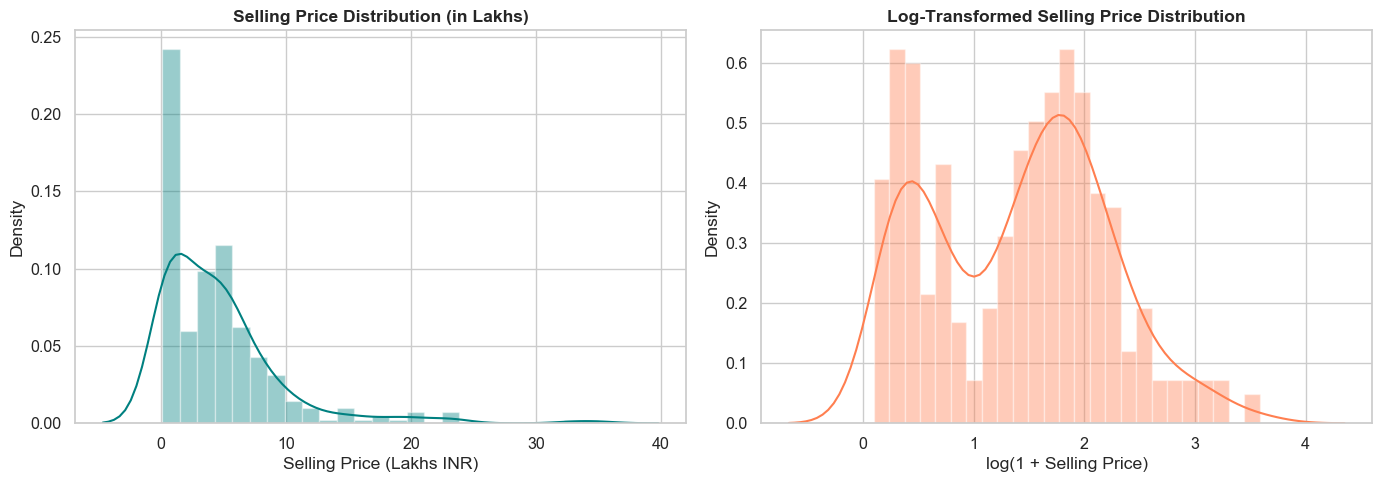

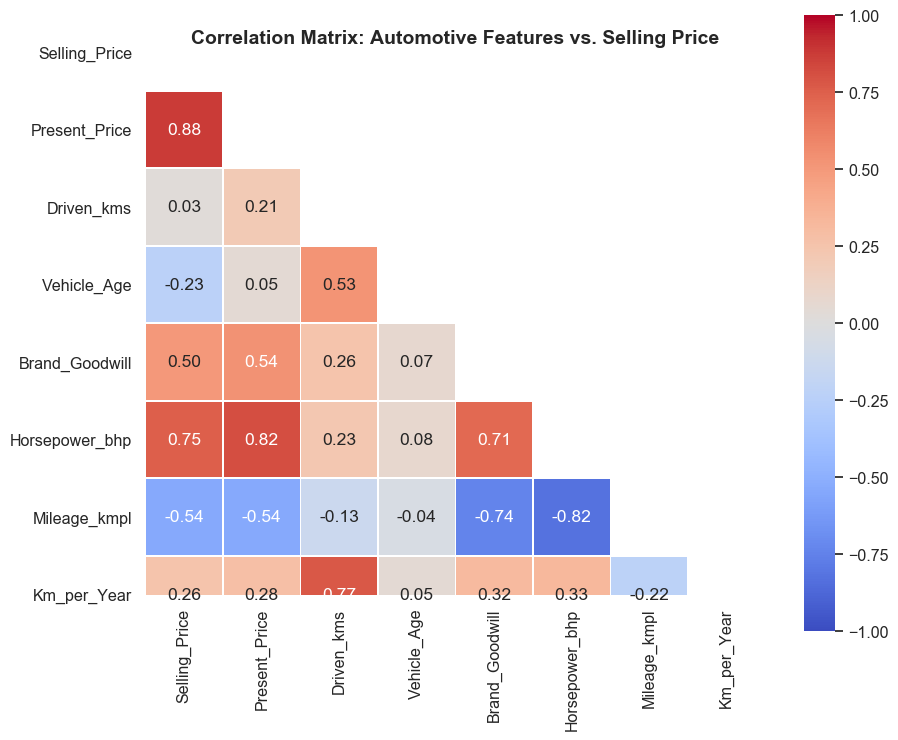

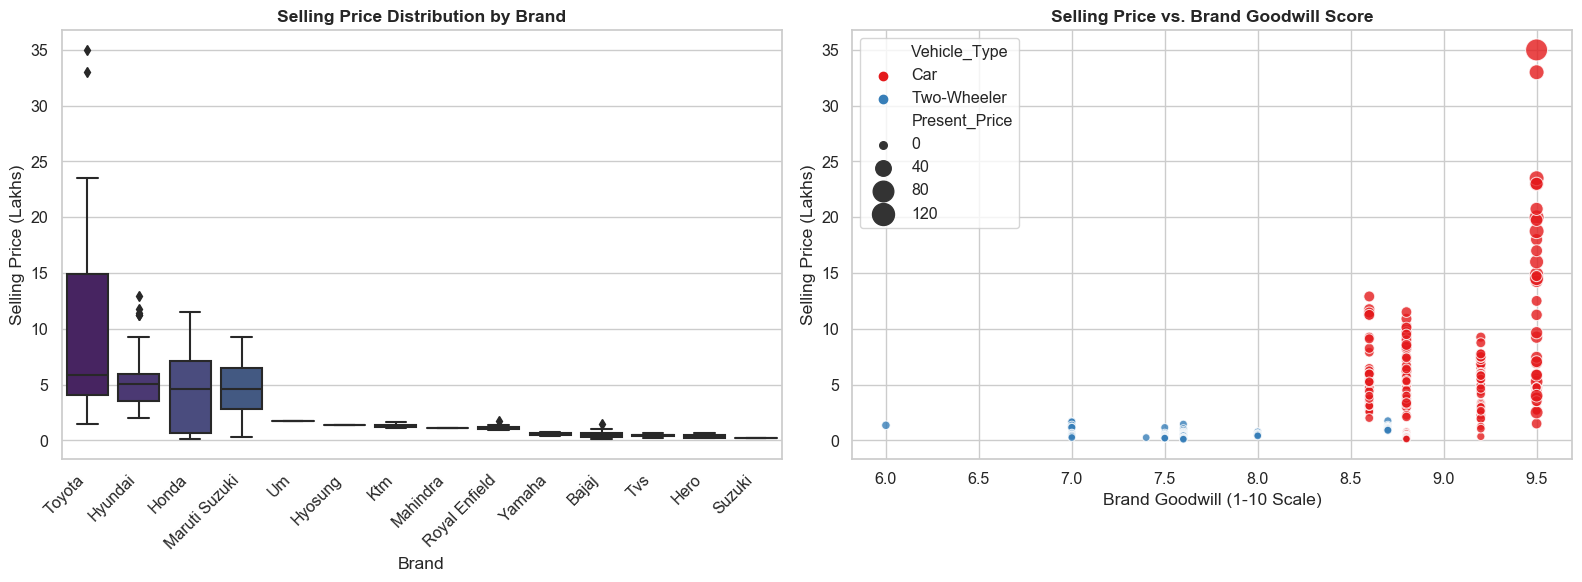

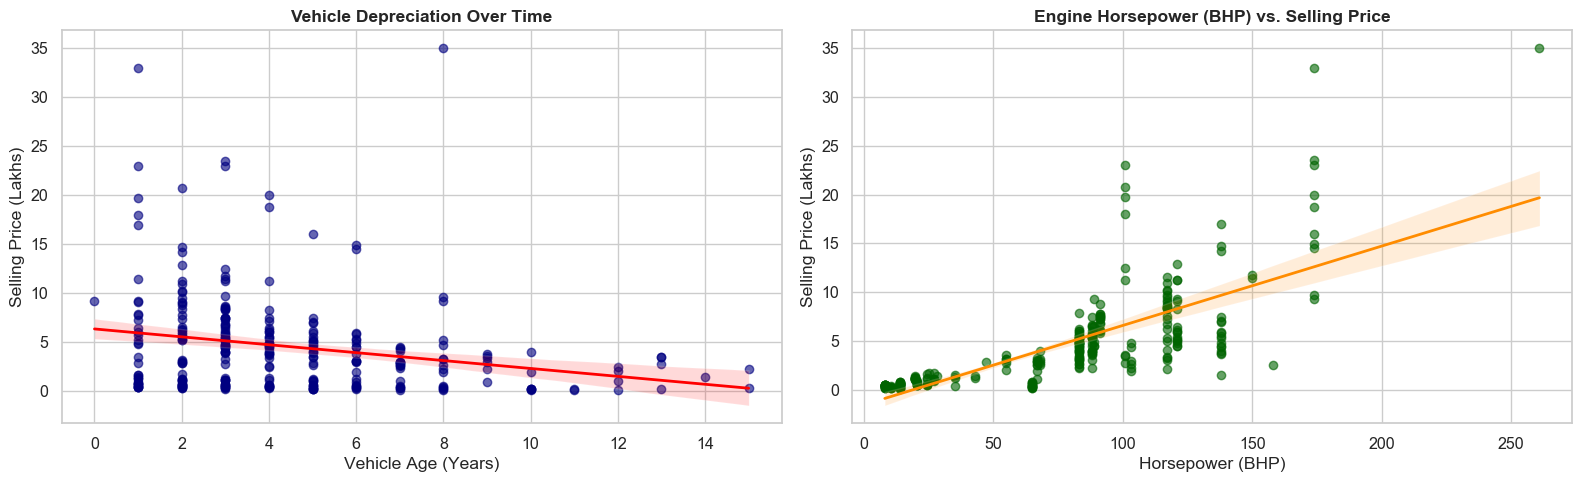

In [5]:
# 1. Price Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.distplot(df['Selling_Price'], kde=True, color='teal', ax=axes[0], bins=25)
axes[0].set_title("Selling Price Distribution (in Lakhs)", fontweight='bold')
axes[0].set_xlabel("Selling Price (Lakhs INR)")
axes[0].set_ylabel("Density")

sns.distplot(np.log1p(df['Selling_Price']), kde=True, color='coral', ax=axes[1], bins=25)
axes[1].set_title("Log-Transformed Selling Price Distribution", fontweight='bold')
axes[1].set_xlabel("log(1 + Selling Price)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()

# 2. Correlation Matrix Heatmap
num_cols = ['Selling_Price', 'Present_Price', 'Driven_kms', 'Vehicle_Age', 
            'Brand_Goodwill', 'Horsepower_bhp', 'Mileage_kmpl', 'Km_per_Year']
plt.figure(figsize=(10, 8))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, mask=mask, square=True, linewidths=0.5)
plt.title("Correlation Matrix: Automotive Features vs. Selling Price", fontweight='bold', fontsize=14)
plt.show()

# 3. Brand Resale & Goodwill Analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
brand_order = df.groupby('Brand')['Selling_Price'].median().sort_values(ascending=False).index
sns.boxplot(x='Brand', y='Selling_Price', data=df, order=brand_order, palette='viridis', ax=axes[0])
axes[0].set_title("Selling Price Distribution by Brand", fontweight='bold')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_ylabel("Selling Price (Lakhs)")

sns.scatterplot(x='Brand_Goodwill', y='Selling_Price', hue='Vehicle_Type', 
                size='Present_Price', sizes=(30, 250), alpha=0.8, data=df, palette='Set1', ax=axes[1])
axes[1].set_title("Selling Price vs. Brand Goodwill Score", fontweight='bold')
axes[1].set_xlabel("Brand Goodwill (1-10 Scale)")
axes[1].set_ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

# 4. Impact of Age and Horsepower
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.regplot(x='Vehicle_Age', y='Selling_Price', data=df, 
            scatter_kws={'alpha': 0.6, 'color': 'navy'}, line_kws={'color': 'red', 'linewidth': 2}, ax=axes[0])
axes[0].set_title("Vehicle Depreciation Over Time", fontweight='bold')
axes[0].set_xlabel("Vehicle Age (Years)")
axes[0].set_ylabel("Selling Price (Lakhs)")

sns.regplot(x='Horsepower_bhp', y='Selling_Price', data=df,
            scatter_kws={'alpha': 0.6, 'color': 'darkgreen'}, line_kws={'color': 'darkorange', 'linewidth': 2}, ax=axes[1])
axes[1].set_title("Engine Horsepower (BHP) vs. Selling Price", fontweight='bold')
axes[1].set_xlabel("Horsepower (BHP)")
axes[1].set_ylabel("Selling Price (Lakhs)")
plt.tight_layout()
plt.show()

## 7. Model Training & Multi-Model Benchmarking

In [6]:
# Feature Matrix & One-Hot Encoding
cat_cols = ['Fuel_Type', 'Selling_type', 'Transmission', 'Vehicle_Type', 'Brand']
ignore_cols = ['Car_Name', 'Selling_Price', 'Year', 'Value_Retention_Ratio']

X_source = df.drop(columns=ignore_cols)
X = pd.get_dummies(X_source, columns=cat_cols, drop_first=True)
y = df['Selling_Price']

# Split 80/20 train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")

# Define candidate models
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.05),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=100, random_state=42)
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
benchmark_results = []
trained_models = {}

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='r2')
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    
    test_r2 = r2_score(y_test, test_pred)
    n, p = len(y_test), X_test.shape[1]
    adj_r2 = 1 - ((1 - test_r2) * (n - 1) / (n - p - 1))
    mae = mean_absolute_error(y_test, test_pred)
    rmse = np.sqrt(mean_squared_error(y_test, test_pred))
    mape = mean_absolute_percentage_error(y_test, test_pred)
    
    benchmark_results.append({
        'Model': name,
        'CV_R2_Mean': cv_scores.mean(),
        'CV_R2_Std': cv_scores.std(),
        'Train_R2': r2_score(y_train, train_pred),
        'Test_R2': test_r2,
        'Adjusted_R2': adj_r2,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE_%': mape * 100
    })

results_df = pd.DataFrame(benchmark_results)
display(results_df.sort_values('Test_R2', ascending=False))

Train Shape: (239, 27), Test Shape: (60, 27)


,Model,CV_R2_Mean,CV_R2_Std,Train_R2,Test_R2,Adjusted_R2,MAE,RMSE,MAPE_%
6,Extra Trees,0.901485,0.092548,1.000000,0.843889,0.712171,0.843083,2.005862,25.251131
3,Decision Tree,0.877786,0.110896,1.000000,0.785661,0.604812,1.123167,2.350366,30.126400
1,Ridge Regression,0.871267,0.041958,0.924923,0.693470,0.434836,1.496814,2.810742,210.509751
5,Gradient Boosting,0.893496,0.104537,0.997595,0.688208,0.425133,1.201569,2.834768,34.254537
0,Linear Regression,0.870513,0.044190,0.925742,0.687739,0.424269,1.517911,2.836896,215.660045
2,Lasso Regression,0.873978,0.032606,0.915794,0.683279,0.416046,1.437682,2.857085,206.612690
4,Random Forest,0.903617,0.069745,0.985391,0.628956,0.315887,1.266070,3.092414,35.432434


## 8. Hyperparameter Optimization (GridSearchCV)

In [7]:
param_grid = {
    'n_estimators': [75, 100, 125],
    'max_depth': [8, 10, 12, None],
    'min_samples_split': [2, 3],
    'min_samples_leaf': [1, 2]
}

base_et = ExtraTreesRegressor(random_state=42)
grid_search = GridSearchCV(
    estimator=base_et,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print(f"Optimal Parameters: {grid_search.best_params_}")
print(f"Best CV R2 Score:   {grid_search.best_score_:.4f}")

# Evaluate tuned model on held-out test data
y_pred_tuned = best_model.predict(X_test)
print(f"\n--- Tuned Extra Trees Model on Held-Out Test Set ---")
print(f"Test R2 Score:    {r2_score(y_test, y_pred_tuned):.4f}")
print(f"Test MAE (Lakhs): {mean_absolute_error(y_test, y_pred_tuned):.4f} (~Rs. {int(mean_absolute_error(y_test, y_pred_tuned)*100000):,})")
print(f"Test RMSE:        {np.sqrt(mean_squared_error(y_test, y_pred_tuned)):.4f}")
print(f"Test MAPE:        {mean_absolute_percentage_error(y_test, y_pred_tuned)*100:.2f}%")

Optimal Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV R2 Score:   0.8938

--- Tuned Extra Trees Model on Held-Out Test Set ---
Test R2 Score:    0.8387
Test MAE (Lakhs): 0.8822 (~Rs. 88,215)
Test RMSE:        2.0391
Test MAPE:        25.71%


## 9. Model Diagnostics & Feature Importances

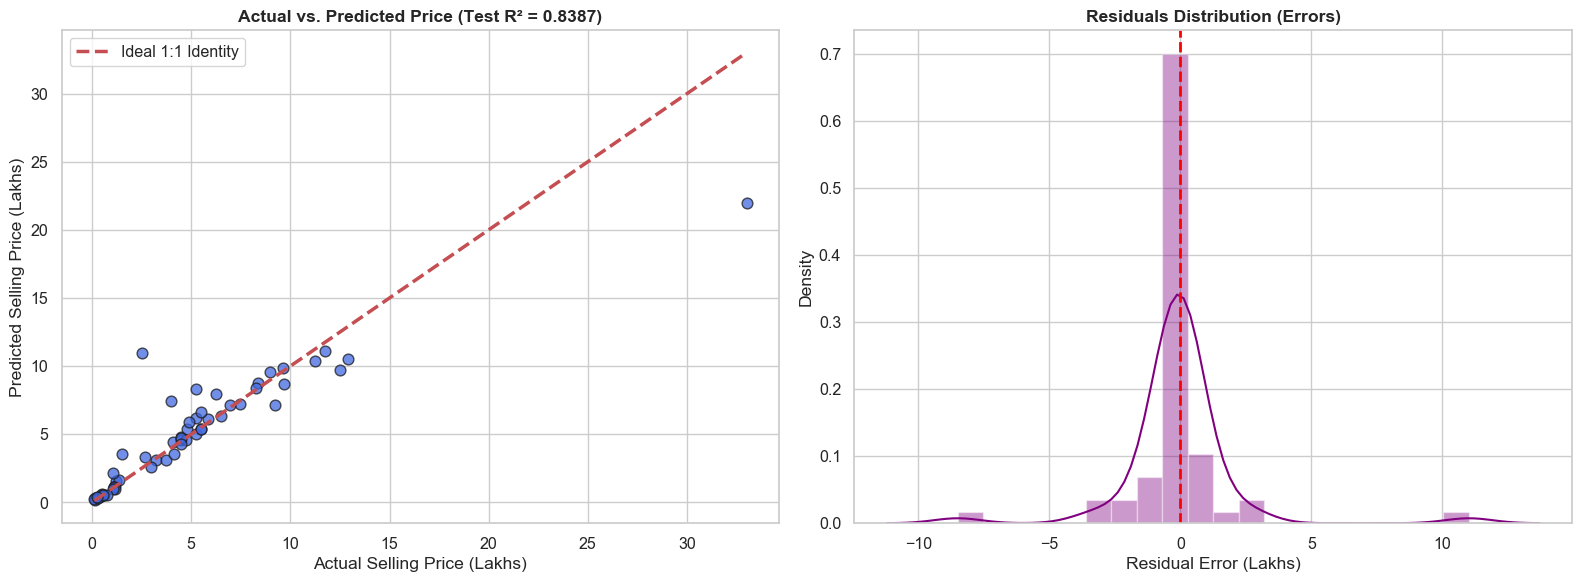

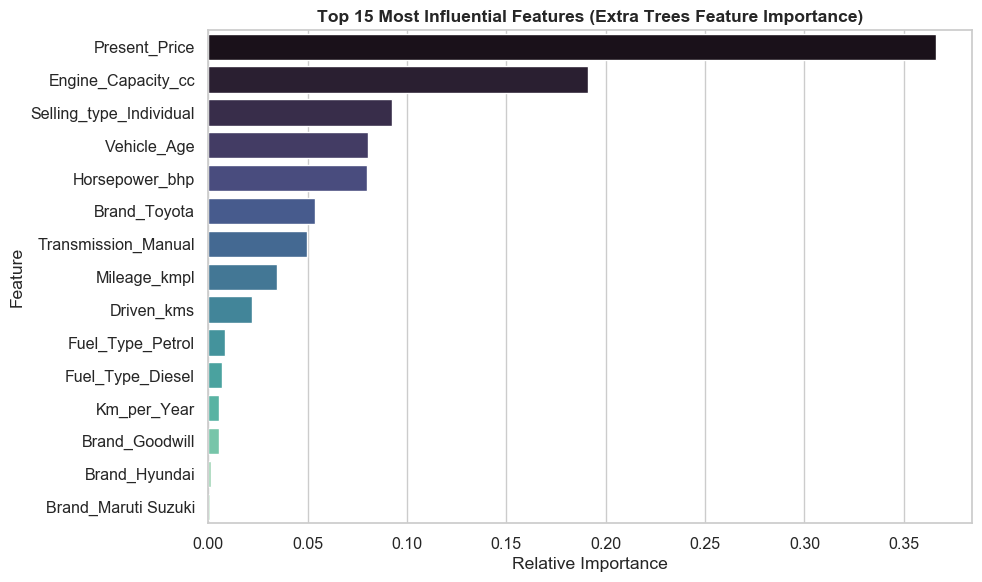

In [8]:
# Actual vs Predicted Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].scatter(y_test, y_pred_tuned, alpha=0.75, color='royalblue', edgecolors='k', s=60)
min_v = min(y_test.min(), y_pred_tuned.min())
max_v = max(y_test.max(), y_pred_tuned.max())
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', lw=2.5, label='Ideal 1:1 Identity')
axes[0].set_title(f"Actual vs. Predicted Price (Test R² = {r2_score(y_test, y_pred_tuned):.4f})", fontweight='bold')
axes[0].set_xlabel("Actual Selling Price (Lakhs)")
axes[0].set_ylabel("Predicted Selling Price (Lakhs)")
axes[0].legend()

# Residual distribution
residuals = y_test - y_pred_tuned
sns.distplot(residuals, kde=True, color='purple', ax=axes[1], bins=20)
axes[1].axvline(0, color='red', linestyle='--', lw=2)
axes[1].set_title("Residuals Distribution (Errors)", fontweight='bold')
axes[1].set_xlabel("Residual Error (Lakhs)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()

# Top 15 Feature Importances
importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
top15 = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top15.values, y=top15.index, palette='mako')
plt.title("Top 15 Most Influential Features (Extra Trees Feature Importance)", fontweight='bold')
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 10. Interactive Production Pricing Function

In [9]:
def predict_car_resale_price(car_name, year, present_price, driven_kms, 
                              fuel_type="Petrol", selling_type="Dealer", 
                              transmission="Manual", owner=0, reference_year=2018):
    brand = extract_brand_name(car_name)
    vehicle_type = classify_vehicle_type(car_name)
    goodwill = BRAND_GOODWILL_MAP.get(brand, 7.0)
    age = max(0, reference_year - year)
    km_per_year = driven_kms / (age + 1)
    hp_bhp, mileage_kmpl, engine_cc = lookup_technical_specs(car_name, vehicle_type, present_price)
    
    row_dict = {
        'Present_Price': present_price,
        'Driven_kms': driven_kms,
        'Owner': owner,
        'Brand_Goodwill': goodwill,
        'Vehicle_Age': age,
        'Km_per_Year': km_per_year,
        'Horsepower_bhp': hp_bhp,
        'Mileage_kmpl': mileage_kmpl,
        'Engine_Capacity_cc': engine_cc,
        'Fuel_Type': fuel_type,
        'Selling_type': selling_type,
        'Transmission': transmission,
        'Vehicle_Type': vehicle_type,
        'Brand': brand
    }
    
    input_df = pd.DataFrame([row_dict])
    cat_cols = ['Fuel_Type', 'Selling_type', 'Transmission', 'Vehicle_Type', 'Brand']
    encoded = pd.get_dummies(input_df, columns=cat_cols, drop_first=True)
    
    for c in X_train.columns:
        if c not in encoded.columns:
            encoded[c] = 0
            
    X_pred = encoded[X_train.columns]
    pred_price = float(best_model.predict(X_pred)[0])
    pred_price = max(0.05, min(present_price * 1.05, pred_price))
    
    return {
        'Vehicle': f"{car_name.title()} ({brand})",
        'Year': year,
        'Original Price': f"Rs. {present_price} Lakhs",
        'Predicted Resale Price': f"Rs. {pred_price:.2f} Lakhs (Rs. {int(pred_price*100000):,})",
        'Estimated Depreciation': f"Rs. {max(0, present_price - pred_price):.2f} Lakhs",
        'Value Retention': f"{(pred_price/present_price)*100:.2f}%",
        'Specs': f"{hp_bhp} BHP | {mileage_kmpl} kmpl | {goodwill}/10 Goodwill"
    }

# Test sample vehicles
samples = [
    {"car_name": "swift", "year": 2015, "present_price": 6.8, "driven_kms": 38000, "fuel_type": "Petrol", "transmission": "Manual"},
    {"car_name": "honda city", "year": 2016, "present_price": 12.0, "driven_kms": 42000, "fuel_type": "Petrol", "transmission": "Automatic"},
    {"car_name": "fortuner", "year": 2017, "present_price": 31.0, "driven_kms": 55000, "fuel_type": "Diesel", "transmission": "Automatic"},
    {"car_name": "Royal Enfield Classic 350", "year": 2016, "present_price": 1.5, "driven_kms": 18000, "fuel_type": "Petrol", "transmission": "Manual"}
]

print("-" * 90)
for s in samples:
    res = predict_car_resale_price(**s)
    for k, v in res.items():
        print(f"  {k:<24}: {v}")
    print("-" * 90)

------------------------------------------------------------------------------------------
  Vehicle                 : Swift (Maruti Suzuki)
  Year                    : 2015
  Original Price          : Rs. 6.8 Lakhs
  Predicted Resale Price  : Rs. 5.14 Lakhs (Rs. 513,719)
  Estimated Depreciation  : Rs. 1.66 Lakhs
  Value Retention         : 75.55%
  Specs                   : 83.0 BHP | 20.5 kmpl | 9.2/10 Goodwill
------------------------------------------------------------------------------------------
  Vehicle                 : Honda City (Honda)
  Year                    : 2016
  Original Price          : Rs. 12.0 Lakhs
  Predicted Resale Price  : Rs. 10.04 Lakhs (Rs. 1,004,459)
  Estimated Depreciation  : Rs. 1.96 Lakhs
  Value Retention         : 83.70%
  Specs                   : 117.0 BHP | 17.8 kmpl | 8.8/10 Goodwill
------------------------------------------------------------------------------------------
  Vehicle                 : Fortuner (Toyota)
  Year                   

## 11. Real-World Applications of Machine Learning in Price Prediction

Machine learning algorithms for vehicle price prediction underpin high-scale business models across digital auto retail, insurance, banking, and fleet operations:

### 1. Algorithmic Buyback & Instant Trade-In Platforms (Cars24, Carvana, Spinny, AutoTrader)
- **Zero-Friction Buyback Quotes:** Customers enter vehicle registration number, mileage, and condition on mobile apps. Regression and gradient boosting ensembles process these against localized regional sales comps to deliver instant, firm cash offers without human inspection delays.
- **Dynamic Price Markdown Management:** For vehicles held in dealer inventory, models dynamically update retail asking prices based on days-on-market, localized demand signals, competitor inventory levels, and seasonal velocity.

### 2. Automotive Insurance Underwriting & Claims Settlement
- **Actual Cash Value (ACV) Calculation:** In cases of severe collisions, theft, or catastrophic weather events, insurers use ML regression to establish accurate, unbiased Actual Cash Value rather than relying on subjective manual adjuster estimates.
- **Diminished Value Assessment:** After repairable accidents, models predict the exact resale impairment suffered by the vehicle due to reported accident history on vehicle history reports (Carfax/AutoCheck comps).

### 3. Auto Financing, Banking & Residual Value Forecasters
- **Lease Residual Value Forecasters:** When leasing a new vehicle, lease payments are calculated based on the asset's projected residual value after 36 to 48 months. Overestimating residual value results in massive portfolio write-downs upon lease maturity; ML models minimize this portfolio risk.
- **Loan-to-Value (LTV) Risk Guardrails:** Safeguards lending banks against underwater loans by predicting resale decay curves across loan terms.

### 4. Fleet Management & Asset Liquidation Timing
- **Optimal Replacement Lifecycle:** Fleet operators (e.g., Hertz, Enterprise, ride-hailing fleets, corporate logistics) determine the exact inflection point where cumulative maintenance expenses exceed resale depreciation, signaling the optimal auction liquidation window.

### 5. Regulatory, Taxation & Import Duty Audits
- Tax authorities and customs officials use standardized machine learning valuation baselines to prevent invoice under-reporting during second-hand vehicle transfers and cross-border auto imports.
